In [6]:
import numpy as np

import matplotlib.pyplot as plt
import scienceplots  # noqa: F401
from matplotlib_inline.backend_inline import set_matplotlib_formats

%matplotlib inline
plt.style.use("science")
set_matplotlib_formats("svg")
extra = 3
plt.rcParams.update({
    "font.size": 14 + extra,
    "axes.titlesize": 17 + extra,
    "axes.labelsize": 15 + extra,
    "xtick.labelsize": 12 + extra,
    "ytick.labelsize": 12 + extra,
    "legend.fontsize": 12 + extra,
    "legend.title_fontsize": 13 + extra,
    "figure.titlesize": 19 + extra,
})

REGION_COLORS = {
    "empty": "#d9d9d9",
    "empty_and_star": "#c84c09",
    "star": "#1f4e79",
    "complete": "#3a7d44",
}

In [7]:
# Nash network
def nash_f1(x, n):
    return 1 / (x - x**2), r"$\frac{1}{\delta-\delta^2}$"


def nash_f2(x, n):
    return 1 / x, r"$\frac{1}{\delta}$"


def nash_f3(x, n):
    return 1 / (x + (n - 2) * x**2), r"$\frac{1}{\delta+(n-2)\delta^2}$"


# Efficient network
def eff_f1(x, n):
    return 1 / (2 * (x - x**2)), r"$\frac{1}{2(\delta-\delta^2)}$"


def eff_f2(x, n):
    return 1 / (2 * x + (n - 2) * x**2), r"$\frac{1}{2\delta+(n-2)\delta^2}$"

In [8]:
n_values = (10, 50, 100)
eps = 1e-3

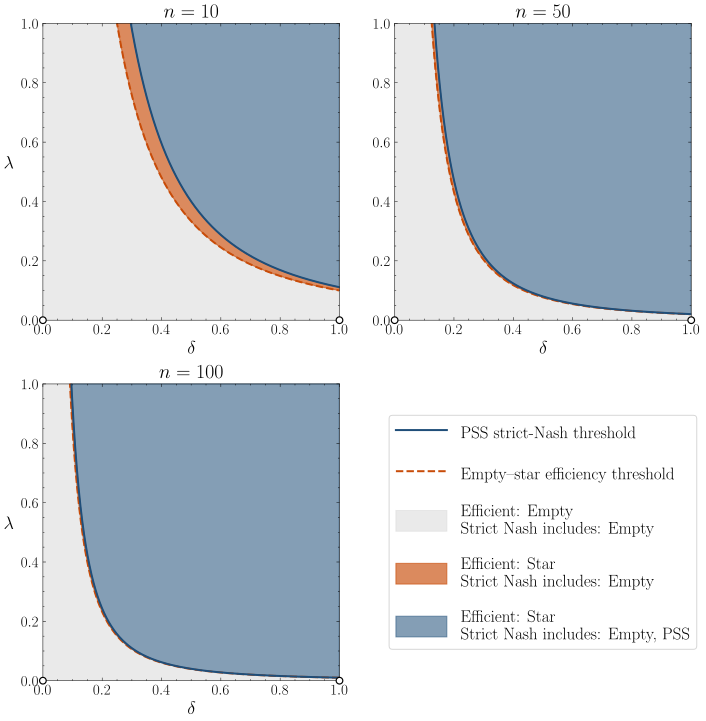

In [9]:
joint_x = np.linspace(eps, 1 - eps, 1000)
lambda_max = 1.0
unit_ticks = np.linspace(0, 1, 6)

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10, 10),
    sharex=False,
    sharey=False,
    layout="constrained",
)
plot_axes = (axes[0, 0], axes[0, 1], axes[1, 0])
legend_ax = axes[1, 1]

for ax, n in zip(plot_axes, n_values, strict=True):
    lambda_nash, _ = nash_f3(joint_x, n)
    lambda_eff, _ = eff_f2(joint_x, n)
    nash_visible = np.minimum(lambda_nash, lambda_max)
    eff_visible = np.minimum(lambda_eff, lambda_max)

    empty_region = ax.fill_between(
        joint_x,
        0,
        eff_visible,
        color=REGION_COLORS["empty"],
        alpha=0.55,
    )
    mismatch_region = ax.fill_between(
        joint_x,
        eff_visible,
        nash_visible,
        where=nash_visible > eff_visible,
        color=REGION_COLORS["empty_and_star"],
        alpha=0.65,
        interpolate=True,
    )
    star_region = ax.fill_between(
        joint_x,
        nash_visible,
        lambda_max,
        where=nash_visible < lambda_max,
        color=REGION_COLORS["star"],
        alpha=0.55,
        interpolate=True,
    )

    (eff_line,) = ax.plot(
        joint_x,
        lambda_eff,
        color=REGION_COLORS["empty_and_star"],
        linestyle="--",
        linewidth=2,
        label="Empty–star efficiency threshold",
    )
    (nash_line,) = ax.plot(
        joint_x,
        lambda_nash,
        color=REGION_COLORS["star"],
        linewidth=2,
        label="PSS strict-Nash threshold",
    )
    ax.set(
        xlim=(0, 1),
        ylim=(0, lambda_max),
        xlabel=r"$\delta$",
        title=rf"$n={n}$",
    )
    ax.set_xticks(unit_ticks)
    ax.set_yticks(unit_ticks)
    ax.scatter(
        [0, 1],
        [0, 0],
        transform=ax.get_xaxis_transform(),
        s=45,
        facecolors="white",
        edgecolors="black",
        linewidths=1.2,
        zorder=5,
        clip_on=False,
    )
    ax.set_aspect("equal", adjustable="box")

for ax in (plot_axes[0], plot_axes[2]):
    ax.set_ylabel(r"$\lambda$", rotation=0, labelpad=12)
legend_ax.set_axis_off()
shared_legend = legend_ax.legend(
    handles=[
        nash_line,
        eff_line,
        empty_region,
        mismatch_region,
        star_region,
    ],
    labels=[
        "PSS strict-Nash threshold",
        "Empty–star efficiency threshold",
        "Efficient: Empty\nStrict Nash includes: Empty",
        "Efficient: Star\nStrict Nash includes: Empty",
        "Efficient: Star\nStrict Nash includes: Empty, PSS",
    ],
    loc="center",
    ncol=1,
    handlelength=3,
    handleheight=1.5,
    labelspacing=1.2,
    fontsize=plt.rcParams["font.size"],
    frameon=True,
)
for text in shared_legend.get_texts():
    text.set_multialignment("left")
for text in shared_legend.get_texts()[2:]:
    text.set_fontweight("bold")
plt.show()

In [10]:
from pathlib import Path

project_root = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "pyproject.toml").is_file()
)
figure_path = project_root / "artifacts" / "extra" / "nash_efficiency_phase_map.pdf"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, format="pdf", bbox_inches="tight")
print(f"Saved: {figure_path.relative_to(project_root)}")

Saved: artifacts/extra/nash_efficiency_phase_map.pdf
